# Kazakh Profanity Detection

A character-level CNN that reads a Kazakh comment and predicts **1 = profanity** or **0 = no profanity**, with the probability P(profanity).

- **Option A** uses the saved model: run the cells and type your own comment.
- **Option B** reruns the whole pipeline (data → training → test evaluation, about 2 minutes on a CPU).

Details: see `README.md` in the repository.

In [1]:
# Get the code and the saved model
import os
REPO_URL = "https://github.com/Kombokonina/kazakh-profanity-detection.git"

if not os.path.exists("predict.py"):
    if os.path.exists("../predict.py"):
        os.chdir("..")                  # opened from the notebooks/ folder
    else:
        !git clone -q {REPO_URL}           # opened in Colab
        os.chdir("kazakh-profanity-detection")
print("code files:", sorted(f for f in os.listdir() if f.endswith(".py")))

code files: ['check_labels.py', 'evaluate.py', 'model.py', 'predict.py', 'prepare_data.py', 'textproc.py', 'train.py', 'verify_source.py']


In [2]:
# Versions (Colab's preinstalled packages are enough)
import platform, torch, numpy, pandas, sklearn, matplotlib
print("Python", platform.python_version())
for m in [torch, numpy, pandas, sklearn, matplotlib]:
    print(m.__name__, m.__version__)

Python 3.13.18
torch 2.15.0+cu132
numpy 2.5.3
pandas 3.0.5
sklearn 1.9.1
matplotlib 3.11.2


## Option A: predict with the saved model

In [3]:
from predict import load_model, predict, show

model, vocab, cfg = load_model()
print("threshold:", cfg["threshold"])
examples = ["Керемет ойын, маған қатты ұнады", "Мал ойын екен", "Өте жаман қосымша, ақшамды қайтарыңдар",
            "Qotaq oyin", "Мал шаруашылығына арналған жақсы кітап"]
for r in predict(examples, model, vocab, cfg):
    show(r)

threshold: 0.5


0 (no profanity)  P(profanity) = 0.0018  |  Керемет ойын, маған қатты ұнады
1 (profanity)  P(profanity) = 0.9999  |  Мал ойын екен
0 (no profanity)  P(profanity) = 0.0323  |  Өте жаман қосымша, ақшамды қайтарыңдар
1 (profanity)  P(profanity) = 0.9966  |  Qotaq oyin
0 (no profanity)  P(profanity) = 0.1695  |  Мал шаруашылығына арналған жақсы кітап


In [4]:
#@title Try your own comment
comment = "Мал ойын екен"  #@param {type:"string"}
show(predict([comment], model, vocab, cfg)[0])

1 (profanity)  P(profanity) = 0.9999  |  Мал ойын екен


## Option B: reproduce everything

Set `RETRAIN = True` to rebuild the splits, train the model and evaluate it on the test set. This overwrites `data/processed/`, `models/` and `results/`. With the versions in `requirements.txt` the files come out identical; with other versions the numbers can differ slightly.

In [5]:
RETRAIN = False  #@param {type:"boolean"}
if RETRAIN:
    !python prepare_data.py
    !python train.py
    !python evaluate.py

## Results

validation: {'precision': 0.946, 'recall': 0.916, 'f1': 0.931} | best epoch 15
{
  "test_examples": 306,
  "threshold": 0.5,
  "precision_profanity": 0.931,
  "recall_profanity": 0.8766,
  "f1_profanity": 0.903,
  "accuracy": 0.9052,
  "confusion_matrix": {
    "true_0_pred_0": 142,
    "true_0_pred_1": 10,
    "true_1_pred_0": 19,
    "true_1_pred_1": 135
  }
}


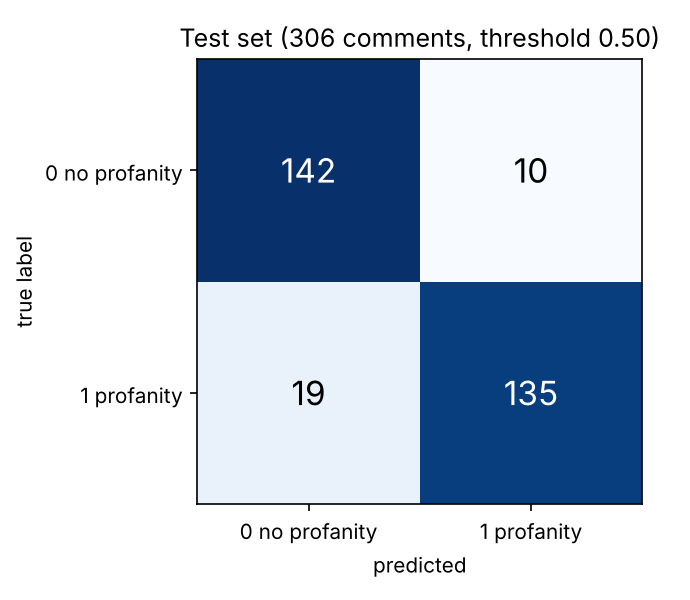

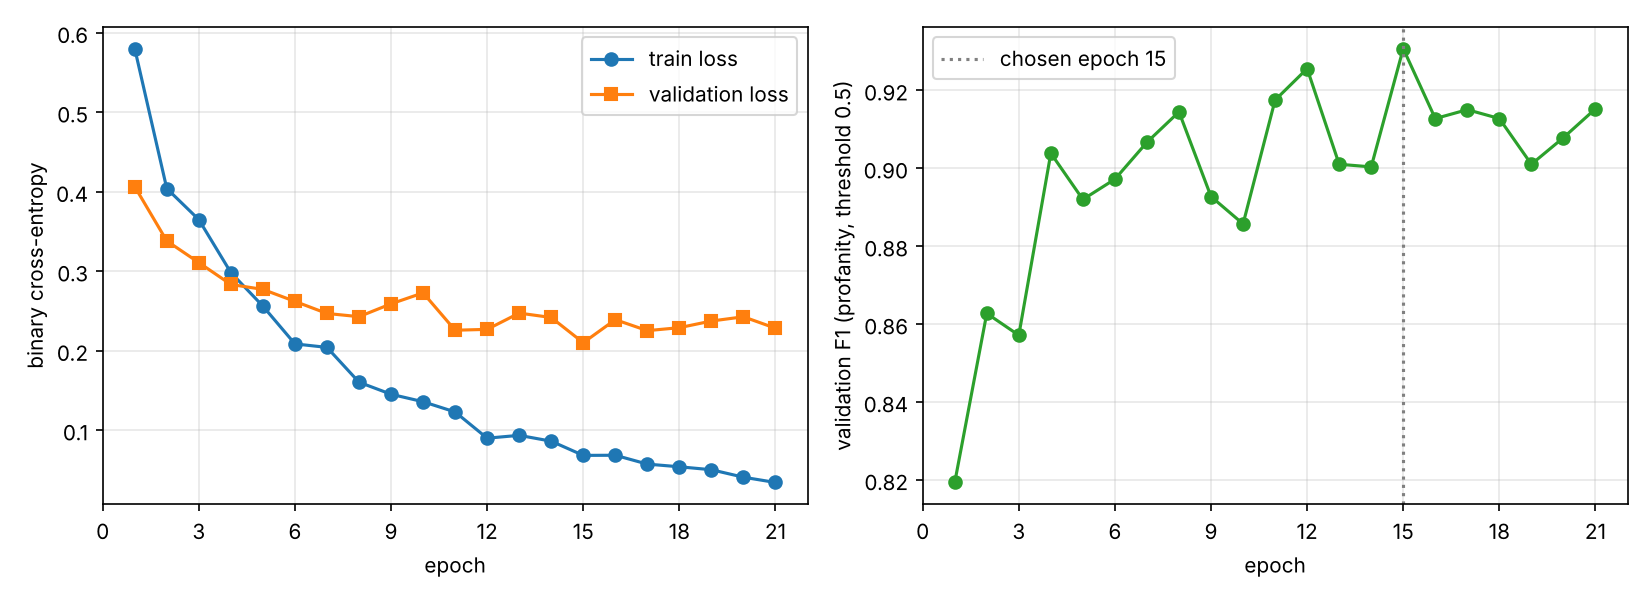

In [6]:
import json
from IPython.display import Image, display

val = json.load(open("results/validation_metrics.json"))
print("validation:", {k: round(v, 3) for k, v in val["at_threshold"].items()}, "| best epoch", val["best_epoch"])
test = json.load(open("results/test_metrics.json"))
print(json.dumps({k: v for k, v in test.items() if k != "by_source"}, indent=2))
display(Image("results/confusion_matrix.png", width=380))
display(Image("results/training_curves.png", width=760))

In [7]:
# Test-set mistakes, from the most confident miss to the most confident false alarm
import pandas as pd
pd.set_option("display.max_colwidth", 100)
pred = pd.read_csv("results/test_predictions.csv")
mistakes = pred[~pred["correct"]].sort_values("probability")
print(len(mistakes), "mistakes out of", len(pred))
mistakes[["label", "probability", "text"]]

29 mistakes out of 306


,label,probability,text
28,1,0.0077,Ам сияқты ұнады👍
64,1,0.0128,өте күшті емес сука
136,1,0.0272,Өте керемет ампл жапмл Салам нолик
305,1,0.0439,Кредит бермейды 667
243,1,0.0445,Есектердін ойнайтын ойыны.Бұл ойынды ойнамандар. Оданда Free Fire ойының ойнандар.
143,1,0.0522,Управлениясын создаватеткен киши гондон
41,1,0.0543,Не звандадын мен каз енген сөздер мен келе жатқан жас кезінде қайтыс болды гой мен каз сурап кей...
94,1,0.0632,Ит қой звандасаң алмайды желіге жазайын десең қуған бірдеңелер өздерің түсінесіңдерма оған өкіме...
283,1,0.0884,Өте жаман ам ам бұл праграма
16,1,0.1151,Wws amshyk samokat ebanuty prilozheniasyda sigip kol koidym sigilip olinder
